In [3]:
# ==============================================================================
# PHẦN 1: KHÁM PHÁ DỮ LIỆU (EDA) VÀ VẼ BIỂU ĐỒ TRỰC QUAN
# Mục tiêu: Đọc dữ liệu gốc (119.390 dòng x 32 cột), tìm dữ liệu khuyết (Missing),
# phát hiện các cột gây lộ đáp án (Data Leakage) và các giá trị ngoại lai (Outliers).
# ==============================================================================

In [4]:
# [BƯỚC 1.1] Khai báo thư viện xử lý dữ liệu (pandas, numpy) và vẽ biểu đồ (seaborn, matplotlib)
import pandas as pd 
import seaborn as sb
import matplotlib.pyplot as plt 
import numpy as np

# Đọc file dữ liệu gốc hotel_bookings_raw.csv (119.390 đơn đặt phòng, 32 cột)
df = pd.read_csv('hotel_bookings_raw.csv')
print("Kich thuoc cua du lieu la: ", df.shape)
df.head() # Xem 5 dòng đầu tiên để nắm cấu trúc bảng

Kich thuoc cua du lieu la:  (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342.0,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0.0,Check-Out,2015-07-01
1,Resort Hotel,0,737.0,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0.0,Check-Out,2015-07-01
2,Resort Hotel,0,7.0,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0.0,Check-Out,2015-07-02
3,Resort Hotel,0,13.0,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0.0,Check-Out,2015-07-02
4,Resort Hotel,0,14.0,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1.0,Check-Out,2015-07-03


In [5]:
# [BƯỚC 1.2] Kiểm tra kiểu dữ liệu (info) và tính tỷ lệ % bị khuyết (Missing Values) của từng cột
# -> Phát hiện: cột 'company' thiếu tới 94.31%, cột 'agent' thiếu 13.69% -> Sẽ xóa ở Phần 2
df.info()
isnull = (df.isnull().sum()/len(df)) * 100
print("===Các cột thiếu dữ liệu(%) ===")
print(isnull[isnull > 0].sort_values(ascending=False).round(2))

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       114615 non-null  float64
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [6]:
# [BƯỚC 1.3] Thống kê mô tả các cột số (min, max, mean, std, tứ phân vị)
# -> Phát hiện bất thường: giá phòng 'adr' có giá trị âm (-6.38) và cực đại tới 5400; có đơn 0 người lớn, 0 trẻ em
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,114615.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,113421.000000,119390.000000,115809.000000
mean,0.370416,104.000916,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.870753,0.062518,0.570793
std,0.482918,106.848755,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.649720,0.245291,0.792892
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.380000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.900000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [7]:
# [BƯỚC 1.4] Kiểm tra phân phối giá trị của các cột dạng chữ (Categorical)
# -> Phát hiện: có khoảng trắng thừa ở đầu/cuối chuỗi và xuất hiện nhãn 'Undefined' ở cột meal, market_segment
columns_text = ['hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type']

for colums in columns_text:
    print("==Colums: ", colums, '==')
    print(df[colums].value_counts())
    print()

==Colums:  hotel ==
hotel
City Hotel        74572
Resort Hotel      37655
 City Hotel        1195
city hotel         1195
CITY HOTEL         1188
City Hotel         1180
resort hotel        614
RESORT HOTEL        612
Resort Hotel        602
 Resort Hotel       577
Name: count, dtype: int64

==Colums:  meal ==
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

==Colums:  market_segment ==
market_segment
Online TA        54787
Offline TA/TO    23508
Groups           19225
Direct           12227
Corporate         5113
Complementary      718
Aviation           229
Undefined            2
Name: count, dtype: int64

==Colums:  distribution_channel ==
distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64

==Colums:  deposit_type ==
deposit_type
No Deposit      95459
Non Refund      13253
 No Deposit      1532
No Deposit       1514


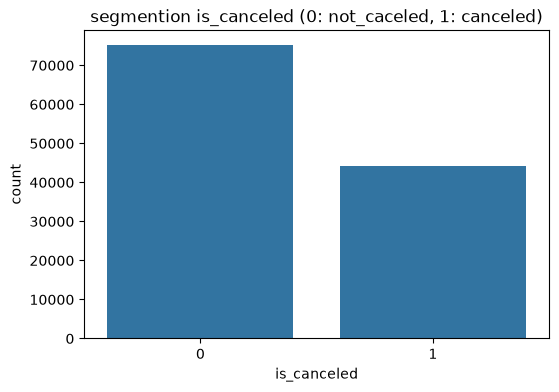

In [8]:
# [BƯỚC 1.5] Vẽ biểu đồ phân bố biến mục tiêu 'is_canceled' (0: Giữ phòng ~63%, 1: Hủy phòng ~37%)
# -> Nhận xét: Dữ liệu có sự chênh lệch giữa 2 lớp nên ngoài Accuracy phải đặc biệt chú trọng chỉ số Recall
plt.figure(figsize=(6, 4))
sb.countplot(data = df, x='is_canceled')
plt.title('segmention is_canceled (0: not_caceled, 1: canceled)')
plt.show()

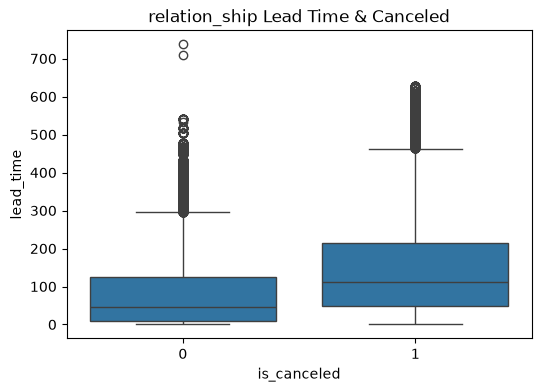

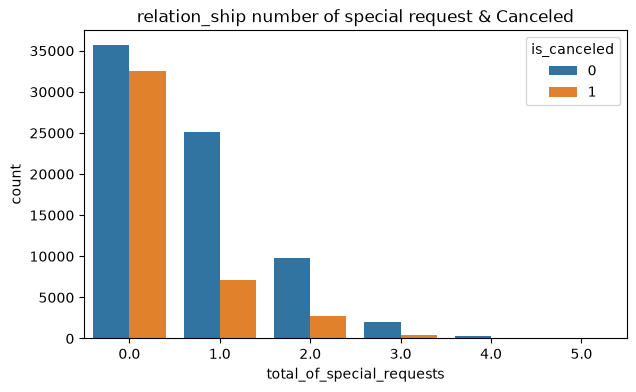

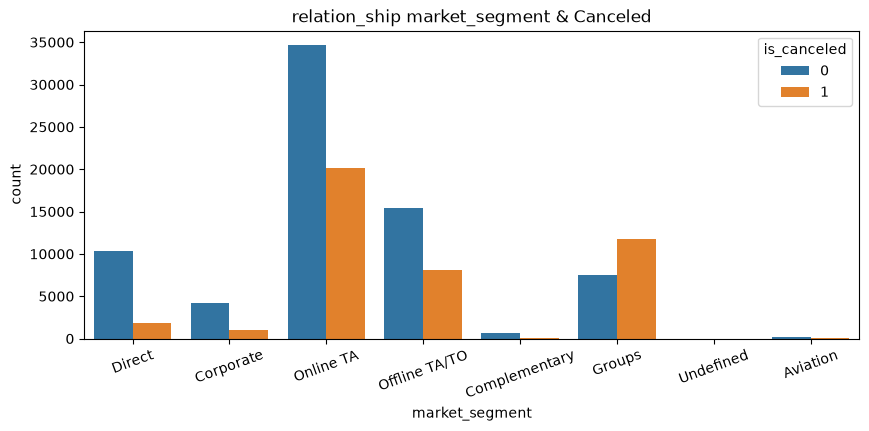

In [9]:
# [BƯỚC 1.6] Vẽ 3 biểu đồ phân tích các yếu tố ảnh hưởng mạnh nhất đến hành vi Hủy phòng:
# 1. Boxplot Lead Time: Đặt trước càng xa ngày nhận phòng (lead_time lớn) -> Tỷ lệ hủy càng cao
plt.figure(figsize=( 6, 4))
sb.boxplot(data = df, x = 'is_canceled', y='lead_time')
plt.title('relation_ship Lead Time & Canceled')
plt.show

# 2. Countplot Special Requests: Khách có nhiều yêu cầu đặc biệt (1-2 yêu cầu) -> Rất ít khi hủy phòng
plt.figure(figsize = (7, 4))
sb.countplot(data = df, x ='total_of_special_requests', hue='is_canceled')
plt.title('relation_ship number of special request & Canceled')
plt.show()

# 3. Countplot Market Segment: Khách đặt qua đại lý trực tuyến (Online TA) có lượng hủy cao nhất
plt.figure( figsize= (10, 4))
sb.countplot(data = df, x='market_segment', hue= 'is_canceled')
plt.title('relation_ship market_segment & Canceled')
plt.xticks(rotation=20)
plt.show()

### Nhận xét Phần 1 - Khám phá dữ liệu:
- **Dữ liệu bẩn phát hiện được:**
  - Cột `company` (thiếu 94%) và `agent` (thiếu 13.6%) bị khuyết quá nhiều -> Cần xóa bỏ.
  - Cột `reservation_status` và `reservation_status_date` cho biết kết quả sau khi khách đã hủy hoặc trả phòng -> Gây lộ đáp án (Data Leakage), bắt buộc phải xóa.
  - Tồn tại các dòng vô lý: tổng số khách (`adults + children + babies`) bằng 0, giá phòng `adr` bị âm hoặc lớn hơn 1000.
- **Quy luật từ biểu đồ:**
  - Tỷ lệ hủy phòng chiếm khoảng 37% tổng số đơn.
  - Khách sạn `City Hotel` có tỷ lệ hủy cao hơn `Resort Hotel`.
  - Thời gian đặt trước (`lead_time`) càng dài thì nguy cơ khách hủy phòng càng cao.

In [11]:
# ==============================================================================
# PHẦN 2: LÀM SẠCH DỮ LIỆU (DATA CLEANING) & TẠO ĐẶC TRƯNG MỚI
# ==============================================================================
# [BƯỚC 2.1] Xóa 4 cột:
# - 'company' (thiếu 94%), 'agent' (thiếu 13.6% và là mã ID đại lý không mang ý nghĩa học)
# - 'reservation_status' & 'reservation_status_date': Chứa kết quả sau khi đã hủy/trả phòng -> Xóa để CHỐNG LỘ ĐÁP ÁN (Data Leakage)
df = df.drop(columns = ['company', 'agent', 'reservation_status', 'reservation_status_date'], errors='ignore')

# Cắt khoảng trắng thừa (.strip()) và chuẩn hóa viết hoa chữ cái đầu (.title())
for col in ['hotel', 'deposit_type', 'customer_type'] :
    df[col] = df[col].str.strip().str.title()

# Xóa các dòng bị trùng lặp hoàn toàn (loại bỏ ~25.700 dòng trùng)
df = df.drop_duplicates()

print("dementions after cleaning ", df.shape)

dementions after cleaning  (93571, 28)


In [12]:
# [BƯỚC 2.2] Chuẩn hóa định dạng tháng và xử lý giá trị 'Undefined':
# - Chuyển tên tháng dạng chữ (January -> December) thành số (1 -> 12)
# - Quy đổi gói ăn 'Undefined' thành 'SC' (Self Catering - Không đặt ăn) theo chuẩn dữ liệu khách sạn
# - Chuyển 'Undefined' ở kênh phân phối/phân khúc thành NaN để bộ SimpleImputer tự trám ở Phần 3
month = {
    'January' : 1,  'February' : 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6, 'July': 7, 'August': 8, 'September' : 9, 'October': 10, 'November': 11, 'December': 12
}
df['arrival_date_month'] = df['arrival_date_month'].replace(month).astype(int)
df['meal'] = df['meal'].replace('Undefined', 'SC')
df['distribution_channel'] = df['distribution_channel'].replace('Undefined', np.nan)
df['market_segment'] = df['market_segment'].replace('Undefined', np.nan)

print("month to numbers:", df['arrival_date_month'].unique())

month to numbers: [ 7  8  9 10 11 12  1  2  3  4  5  6]


In [13]:
# [BƯỚC 2.3] Lọc bỏ các dòng vô lý (Outliers) và tạo đặc trưng mới (Feature Engineering):
# - Loại bỏ các đơn mà tổng số khách (người lớn + trẻ em + em bé) = 0
# - Loại bỏ các đơn có giá phòng trung bình (adr) bị âm (< 0) hoặc quá ảo (> 1000)
# - Tạo cột mới 'total_nights' = số đêm cuối tuần + số đêm trong tuần
# -> Sau Phần 2: Từ 119.390 dòng thô còn lại 93.398 dòng sạch x 29 cột!
df = df[(df['adults'] + df['children'] + df['babies']) !=0]
df = df[~((df['adr'] < 0) | (df['adr']>1000))]
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

print("Dementions after part 2:", df.shape)

Dementions after part 2: (93398, 29)


In [14]:
# ==============================================================================
# PHẦN 3: TIỀN XỬ LÝ DỮ LIỆU (PREPROCESSING) & CHỐNG RÒ RỈ (DATA LEAKAGE)
# ==============================================================================

In [15]:
# [BƯỚC 3.1] Tách biến đầu vào X (28 cột) và nhãn mục tiêu y ('is_canceled')
# NGUYÊN TẮC VÀNG CHỐNG DATA LEAKAGE: Chia Train (80% = 74.718 dòng) và Test (20% = 18.680 dòng) TRƯỚC KHI chuẩn hóa!
from sklearn.model_selection import train_test_split

X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

# Phân loại tự động: 19 cột dạng số (num_cols) và 9 cột dạng chữ (cat_cols)
num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("number of num:", len(num_cols), "number of text:", len(cat_cols))
print("Train:", X_train.shape, "| Test:", X_test.shape)

number of num: 19 number of text: 9
Train: (74718, 28) | Test: (18680, 28)


In [16]:
# [BƯỚC 3.2] Chuẩn hóa dữ liệu (Chỉ .fit_transform trên Train, chỉ .transform trên Test):
# 1. Cột số (19 cột): Trám khuyết bằng Trung vị (median) + Đưa về phân phối chuẩn (StandardScaler: mean=0, std=1)
# 2. Cột chữ (9 cột): Trám khuyết bằng giá trị phổ biến nhất (most_frequent) + Mã hóa One-Hot (ra 209 cột nhị phân)
# 3. Ghép lại bằng np.hstack -> Tạo ma trận 228 đặc trưng đầu vào (19 + 209 = 228 cột) cho Mạng Nơ-ron!
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_imputer = SimpleImputer(strategy='median')
X_train_num = num_imputer.fit_transform(X_train[num_cols])
X_test_num = num_imputer.transform(X_test[num_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.transform(X_test[cat_cols])

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = encoder.fit_transform(X_train_cat)
X_test_cat = encoder.transform(X_test_cat)

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)

X_train_final: (74718, 228)
X_test_final: (18680, 228)


### Nhận xét Phần 2 & 3 - Làm sạch và Tiền xử lý dữ liệu:
- Sau khi xóa dòng trùng lặp, lọc bỏ các đơn 0 khách và giá `adr` bất thường, dữ liệu sạch còn lại **93.398 dòng và 29 cột** (đã tạo thêm cột tổng số đêm `total_nights`).
- **Nguyên tắc chống lộ đề (Data Leakage):** Bắt buộc chia `Train (80% - 74.718 dòng)` và `Test (20% - 18.680 dòng)` trước. Các bộ tiền xử lý (`SimpleImputer`, `OneHotEncoder`, `StandardScaler`) chỉ được học quy luật (`.fit_transform()`) trên tập `Train` rồi mới áp dụng (`.transform()`) sang tập `Test`.
- Sau khi ghép cột số và cột chữ bằng `np.hstack`, mỗi đơn đặt phòng có **228 đặc trưng đầu vào** để đưa vào mạng nơ-ron.

In [17]:
# ==============================================================================
# PHẦN 4: XÂY DỰNG VÀ HUẤN LUYỆN MẠNG NƠ-RON CƠ SỞ (BASELINE MLP MODEL)
# ==============================================================================

Epoch 1/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 896us/step - accuracy: 0.7896 - loss: 0.4319 - val_accuracy: 0.8069 - val_loss: 0.3966
Epoch 2/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step - accuracy: 0.8190 - loss: 0.3760 - val_accuracy: 0.8185 - val_loss: 0.3806
Epoch 3/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 466us/step - accuracy: 0.8272 - loss: 0.3618 - val_accuracy: 0.8234 - val_loss: 0.3723
Epoch 4/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - accuracy: 0.8322 - loss: 0.3531 - val_accuracy: 0.8265 - val_loss: 0.3692
Epoch 5/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step - accuracy: 0.8357 - loss: 0.3466 - val_accuracy: 0.8280 - val_loss: 0.3674
Epoch 6/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 529us/step - accuracy: 0.8391 - loss: 0.3415 - val_accuracy: 0.8288 - val_loss: 0.3670
Epoch 7/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 531us/step - accuracy: 0.8406 - loss: 0.3373 - val_accuracy: 0.8293 - val_loss: 0.3661
Epoch 8/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step - accuracy: 0.8428 - loss: 0.3336 - 

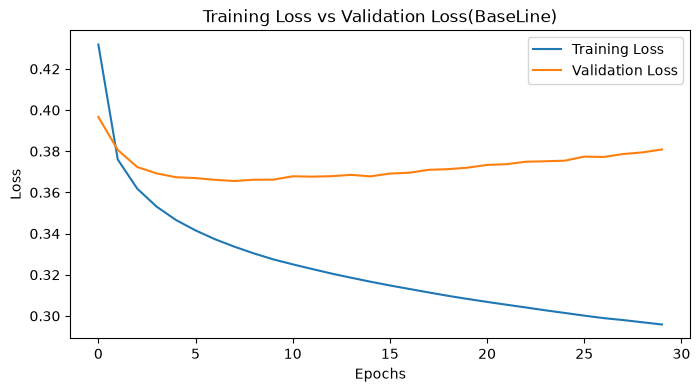

In [18]:
# [BƯỚC 4.1] Thiết kế mạng Nơ-ron Baseline:
# - Kiến trúc: Input(228) -> Dense(64, ReLU) -> Dense(32, ReLU) -> Output Dense(1, Sigmoid nén xác suất về 0..1)
# - Chú ý: Mô hình Baseline CHƯA có Dropout và CHƯA có EarlyStopping -> Chạy 30 Epochs để quan sát hiện tượng Học vẹt (Overfitting)
import time
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

baseline_model = Sequential([
    Input(shape=(X_train_final.shape[1],)),
    Dense (64, activation='relu'),
    Dense (32, activation='relu'),
    Dense (1, activation='sigmoid')
])

baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
history = baseline_model.fit(X_train_final, y_train, epochs=30, batch_size=128, validation_split=0.2)
baseline_time = time.time() - start_time

print("Train time(s):", round(baseline_time, 2))

# Vẽ biểu đồ Loss: Từ Epoch 8, Training Loss giảm nhưng Validation Loss tăng ngược lên -> Dấu hiệu rõ rệt của Overfitting!
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training Loss vs Validation Loss(BaseLine)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

584/584 ━━━━━━━━━━━━━━━━━━━━ 0s 153us/step
Accuracy on Test: 83.06 %
Rate canceled booking (Recall): 55.65 %


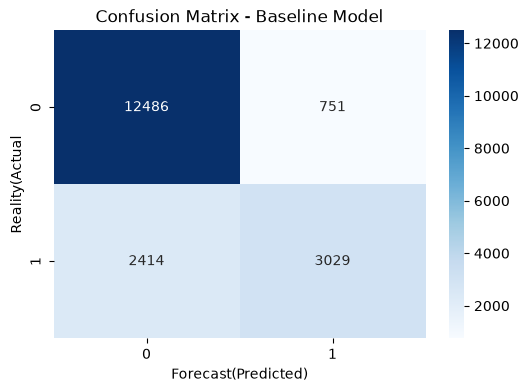

In [22]:
# [BƯỚC 4.2] Đánh giá mô hình Baseline trên tập Test độc lập (18.680 đơn):
# - Kết quả: Accuracy đạt 83.06%, nhưng Recall (tỷ lệ bắt trúng khách hủy) chỉ đạt 55.65%!
# - Ma trận nhầm lẫn: Bắt trúng 3.028 đơn hủy, nhưng bỏ lọt tới 2.414 đơn hủy (False Negative quá cao)
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

y_pred_prob = baseline_model.predict(X_test_final)
y_pred = (y_pred_prob >= 0.5).astype(int)

base_line_acc = accuracy_score(y_test, y_pred)
baseline_recall = recall_score(y_test, y_pred)

print("Accuracy on Test:", round(base_line_acc *100, 2), "%")
print("Rate canceled booking (Recall):", round(baseline_recall *100, 2), "%")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize =(6, 4))
sb.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Baseline Model')
plt.xlabel('Forecast(Predicted)')
plt.ylabel('Reality(Actual')
plt.show()

### Nhận xét Phần 4 - Đánh giá mô hình Baseline:
- **Hiện tượng Học vẹt (Overfitting):** Nhìn biểu đồ Loss, từ vòng lặp (Epoch) thứ 8 trở đi, đường `Training Loss` tiếp tục giảm sâu nhưng đường `Validation Loss` lại tăng ngược lên (từ 0.366 lên 0.382). Nguyên nhân là do mạng chưa có lớp chống học vẹt `Dropout` và chưa có phanh tự động `EarlyStopping`.
- **Kết quả trên tập Test:** Độ chính xác (`Accuracy`) đạt **83.06%**, nhưng tỷ lệ bắt trúng khách hủy phòng (`Recall`) chỉ đạt **55.65%** (bỏ lọt tới 2.414 đơn hủy phòng). Do đó cần tối ưu tham số ở Phần 5.

In [20]:
# ==============================================================================
# PHẦN 5: TỐI ƯU SIÊU THAM SỐ (HYPERPARAMETER TUNING 2 GIAI ĐOẠN)
# Mục tiêu: Thêm Dropout + EarlyStopping để trị dứt điểm Overfitting và nâng cao Recall
# ==============================================================================

In [30]:
# [BƯỚC 5.1] Viết hàm tự động hóa huấn luyện (run_experiment) để thử nghiệm nhiều cấu hình:
# - Tích hợp lớp Dropout sau mỗi lớp Dense để tắt ngẫu nhiên nơ-ron chống học vẹt
# - Tích hợp EarlyStopping(patience=5, restore_best_weights=True): Tự động phanh lại khi val_loss không giảm sau 5 epoch và khôi phục bộ trọng số tốt nhất
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

def run_experiment(layers_list, dropout_rate, lr, batch_size=128):
    model = Sequential()
    model.add(Input(shape=(X_train_final.shape[1],)))

    for units in layers_list:
        model.add(Dense(units, activation='relu'))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    start = time.time()
    hist = model.fit(X_train_final, y_train, epochs=50, batch_size=batch_size,validation_split=0.2, callbacks=[early_stop], verbose=0)
    train_time = round(time.time() - start, 2)

    return{
        'layers': str(layers_list),
        'dropout': dropout_rate,
        'lr':lr,
        'batch_size': batch_size,
        'val_loss': round(min(hist.history['val_loss']), 4),
        'val_acc': round(max(hist.history['val_accuracy'])*100, 2),
        'epochs_run': len(hist.history['loss']),
        'time_s': train_time
    }

In [31]:
# [BƯỚC 5.2] GIAI ĐOẠN 1 (Stage 1): Cố định batch_size = 128, thử 8 cấu hình khác nhau về:
# - Số lớp & số nơ-ron: [64, 32], [128, 64], [128, 64, 32], [256, 128, 64]
# - Tỷ lệ Dropout: 0.0, 0.2, 0.3 | Tốc độ học (Learning Rate): 0.001 và 0.0005
configs_stage1=[
    ([64, 32], 0.0, 0.001),
    ([64, 32], 0.2, 0.001),
    ([128, 64], 0.2, 0.001),
    ([128, 64], 0.3, 0.0005),
    ([128, 64, 32], 0.0, 0.001),
    ([128, 64, 32], 0.2, 0.001),
    ([128, 64, 32], 0.2, 0.0005),
    ([256, 128, 64], 0.2, 0.0005)
]

results = []
for layers, drop, lr in configs_stage1:
    res = run_experiment(layers, drop, lr, batch_size=128)
    results.append(res)
    print("Done:", res)

df_stage1 = pd.DataFrame(results).sort_values(by='val_acc', ascending=False)
df_stage1

Done: {'layers': '[64, 32]', 'dropout': 0.0, 'lr': 0.001, 'batch_size': 128, 'val_loss': 0.3607, 'val_acc': 83.17, 'epochs_run': 15, 'time_s': 3.71}
Done: {'layers': '[64, 32]', 'dropout': 0.2, 'lr': 0.001, 'batch_size': 128, 'val_loss': 0.347, 'val_acc': 83.91, 'epochs_run': 19, 'time_s': 4.94}
Done: {'layers': '[128, 64]', 'dropout': 0.2, 'lr': 0.001, 'batch_size': 128, 'val_loss': 0.3516, 'val_acc': 83.67, 'epochs_run': 15, 'time_s': 5.12}
Done: {'layers': '[128, 64]', 'dropout': 0.3, 'lr': 0.0005, 'batch_size': 128, 'val_loss': 0.3444, 'val_acc': 84.13, 'epochs_run': 26, 'time_s': 8.59}
Done: {'layers': '[128, 64, 32]', 'dropout': 0.0, 'lr': 0.001, 'batch_size': 128, 'val_loss': 0.3641, 'val_acc': 83.2, 'epochs_run': 10, 'time_s': 3.25}
Done: {'layers': '[128, 64, 32]', 'dropout': 0.2, 'lr': 0.001, 'batch_size': 128, 'val_loss': 0.3484, 'val_acc': 84.07, 'epochs_run': 24, 'time_s': 8.37}
Done: {'layers': '[128, 64, 32]', 'dropout': 0.2, 'lr': 0.0005, 'batch_size': 128, 'val_loss': 

,layers,dropout,lr,batch_size,val_loss,val_acc,epochs_run,time_s
3,"[128, 64]",0.3,0.0005,128,0.3444,84.13,26,8.59
5,"[128, 64, 32]",0.2,0.0010,128,0.3484,84.07,24,8.37
6,"[128, 64, 32]",0.2,0.0005,128,0.3449,84.02,23,8.15
7,"[256, 128, 64]",0.2,0.0005,128,0.3495,83.97,18,10.43
1,"[64, 32]",0.2,0.0010,128,0.3470,83.91,19,4.94
2,"[128, 64]",0.2,0.0010,128,0.3516,83.67,15,5.12
4,"[128, 64, 32]",0.0,0.0010,128,0.3641,83.20,10,3.25
0,"[64, 32]",0.0,0.0010,128,0.3607,83.17,15,3.71


Done stage 2: {'layers': '[128, 64]', 'dropout': 0.3, 'lr': 0.0005, 'batch_size': 64, 'val_loss': 0.3491, 'val_acc': 83.81, 'epochs_run': 25, 'time_s': 12.17}
Done stage 2: {'layers': '[128, 64]', 'dropout': 0.3, 'lr': 0.0005, 'batch_size': 256, 'val_loss': 0.3438, 'val_acc': 84.09, 'epochs_run': 48, 'time_s': 10.25}
Done stage 2: {'layers': '[128, 64, 32]', 'dropout': 0.2, 'lr': 0.0001, 'batch_size': 64, 'val_loss': 0.3438, 'val_acc': 84.27, 'epochs_run': 50, 'time_s': 26.4}
Done stage 2: {'layers': '[128, 64, 32]', 'dropout': 0.2, 'lr': 0.001, 'batch_size': 256, 'val_loss': 0.3442, 'val_acc': 84.41, 'epochs_run': 23, 'time_s': 5.81}


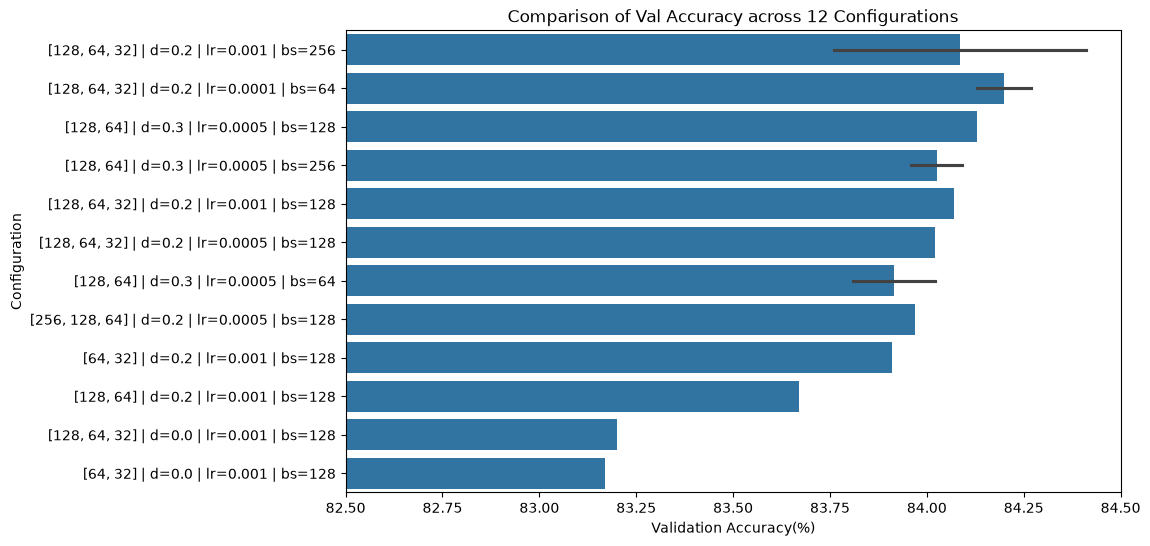

,layers,dropout,lr,batch_size,val_acc,epochs_run,time_s
0,"[128, 64, 32]",0.2,0.0010,256,84.41,23,5.81
1,"[128, 64, 32]",0.2,0.0001,64,84.27,50,26.40
2,"[128, 64]",0.3,0.0005,128,84.13,26,8.59
3,"[128, 64, 32]",0.2,0.0001,64,84.13,50,26.90
4,"[128, 64]",0.3,0.0005,256,84.09,48,10.25
5,"[128, 64, 32]",0.2,0.0010,128,84.07,24,8.37
6,"[128, 64, 32]",0.2,0.0005,128,84.02,23,8.15
7,"[128, 64]",0.3,0.0005,64,84.02,28,14.08
8,"[256, 128, 64]",0.2,0.0005,128,83.97,18,10.43
9,"[128, 64]",0.3,0.0005,256,83.96,40,9.15


In [33]:
# [BƯỚC 5.3] GIAI ĐOẠN 2 (Stage 2): Lấy 2 kiến trúc tốt nhất ([128, 64] và [128, 64, 32])
# để thử nghiệm tiếp với batch_size = 64 và batch_size = 256 -> Tổng cộng 12 lượt thử nghiệm, vẽ biểu đồ so sánh
configs_stage2 =[
    ([128, 64], 0.3, 0.0005, 64),
    ([128, 64], 0.3, 0.0005, 256),
    ([128, 64, 32], 0.2, 0.0001, 64),
    ([128, 64, 32], 0.2, 0.001, 256)
]

for layers, drop, lr, b_size in configs_stage2:
    res = run_experiment(layers, drop, lr, batch_size=b_size)
    results.append(res)
    print("Done stage 2:", res)

df_all = pd.DataFrame(results).sort_values(by='val_acc', ascending=False).reset_index(drop=True)
df_all['config_name'] = df_all['layers'] + " | d=" + df_all['dropout'].astype(str) + " | lr=" + df_all['lr'].astype(str) + " | bs=" + df_all['batch_size'].astype(str)

plt.figure(figsize=(10, 6))
sb.barplot(data=df_all, x='val_acc', y='config_name')
plt.xlim(82.5, 84.5)
plt.title('Comparison of Val Accuracy across 12 Configurations')
plt.xlabel('Validation Accuracy(%)')
plt.ylabel('Configuration')
plt.show()

df_all[['layers', 'dropout', 'lr', 'batch_size', 'val_acc', 'epochs_run', 'time_s']]

Epoch 1/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7660 - loss: 0.4767 - val_accuracy: 0.8047 - val_loss: 0.4095
Epoch 2/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step - accuracy: 0.8037 - loss: 0.4096 - val_accuracy: 0.8140 - val_loss: 0.3882
Epoch 3/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.8128 - loss: 0.3893 - val_accuracy: 0.8213 - val_loss: 0.3776
Epoch 4/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 650us/step - accuracy: 0.8204 - loss: 0.3786 - val_accuracy: 0.8246 - val_loss: 0.3705
Epoch 5/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 677us/step - accuracy: 0.8242 - loss: 0.3706 - val_accuracy: 0.8260 - val_loss: 0.3661
Epoch 6/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 648us/step - accuracy: 0.8273 - loss: 0.3648 - val_accuracy: 0.8273 - val_loss: 0.3634
Epoch 7/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 661us/step - accuracy: 0.8299 - loss: 0.3603 - val_accuracy: 0.8296 - val_loss: 0.3604
Epoch 8/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 661us/step - accuracy: 0.8310 - loss: 0.3568 - va

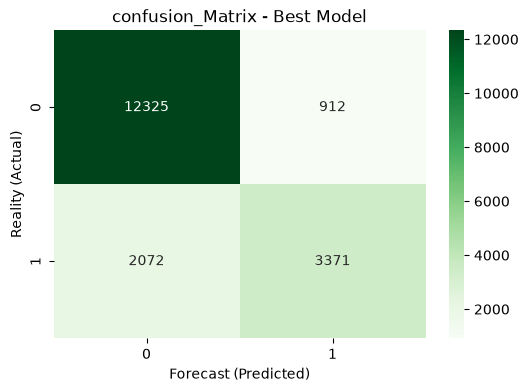

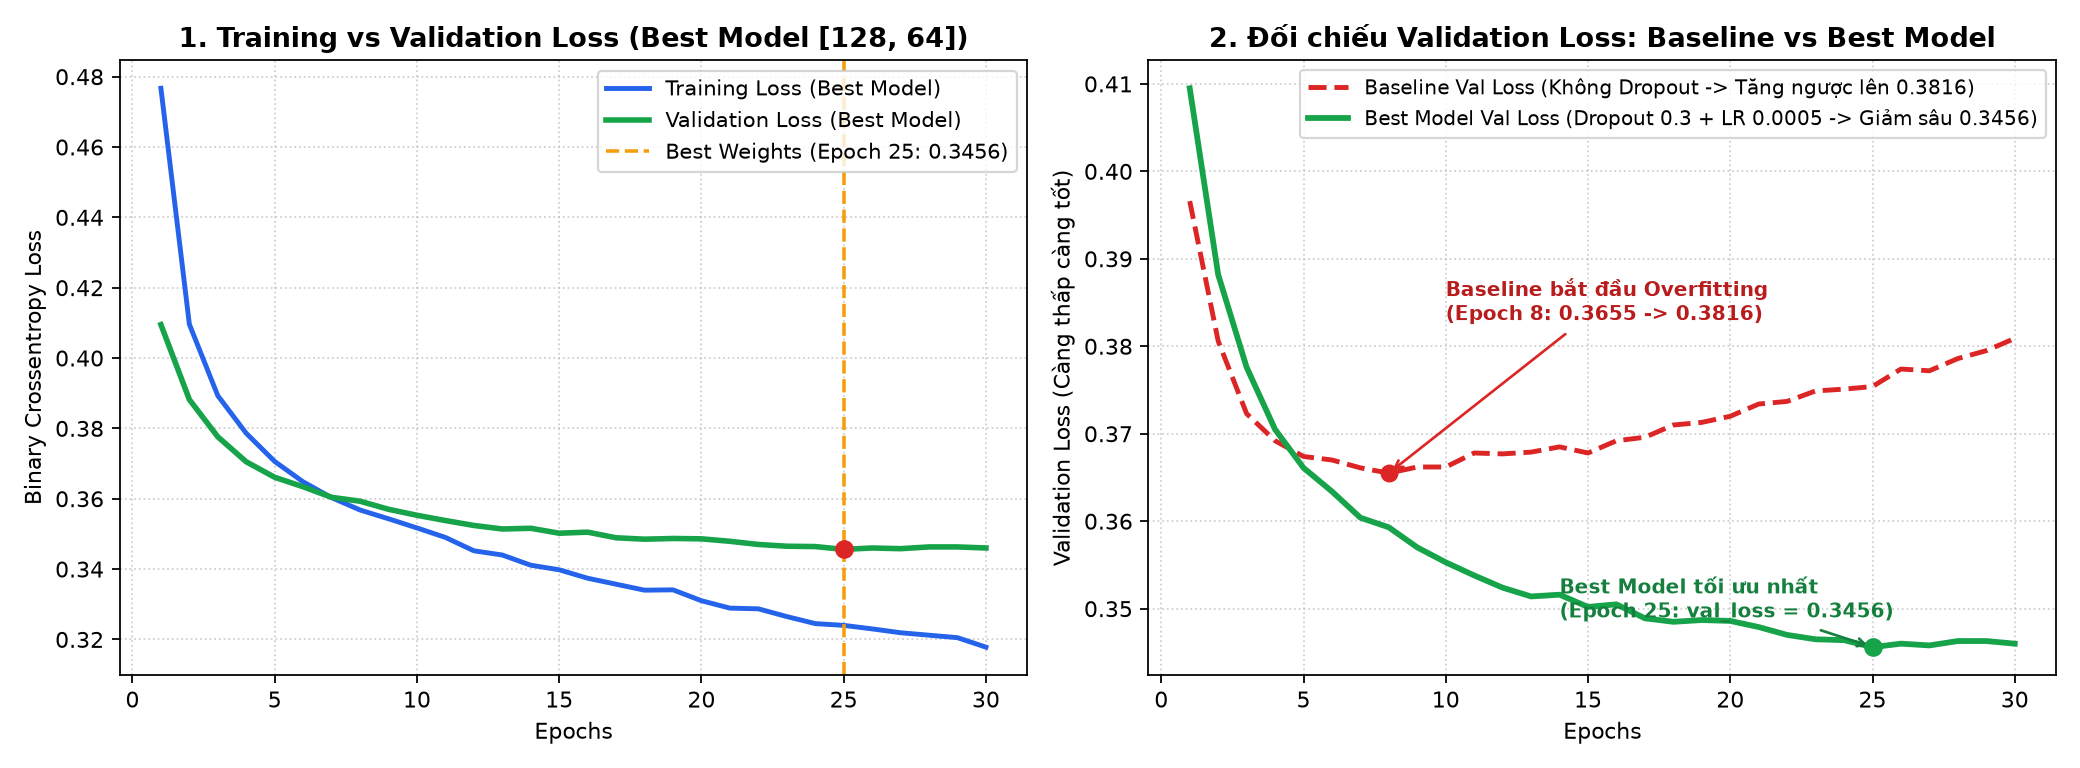

In [37]:
# [BƯỚC 5.4] HUẤN LUYỆN MÔ HÌNH TỐT NHẤT (BEST MODEL) & SO SÁNH VỚI BASELINE TRÊN TẬP TEST:
# - Cấu hình Best Model: Kiến trúc [128, 64] + Dropout(0.3) + Adam(lr=0.0005) + Batch Size 128 + EarlyStopping(patience=5)
# - ĐỘT PHÁ KẾT QUẢ TRÊN TẬP TEST (18.680 đơn):
#   + Test Accuracy: Tăng từ 83.06% -> 84.03% (đoán đúng thêm 181 đơn)
#   + Test Recall (Bắt khách hủy): Tăng vọt từ 55.65% -> 61.93% (tăng +6.28%, bắt trúng 3.370 đơn hủy, tức phát hiện thêm 342 đơn hủy phòng!)
best_model = Sequential([
    Input(shape=(X_train_final.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

best_model.compile(optimizer=Adam(learning_rate=0.0005), loss='binary_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience = 5, restore_best_weights=True)

best_hist = best_model.fit(X_train_final, y_train, epochs=50, batch_size=128, validation_split=0.2, callbacks=[early_stop])

y_pred_best = (best_model.predict(X_test_final) >= 0.5).astype(int)
best_acc = accuracy_score(y_test, y_pred_best)
best_recall = recall_score(y_test, y_pred_best)

print("Baseline -> Test Acc:", round(base_line_acc *100, 2), "% | Recall:", round(baseline_recall * 100, 2), "%")
print("Best Model -> Test Acc:", round(best_acc * 100, 2), "% | Recall:", round(best_recall * 100, 2), "%")
cm_best = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 4))
sb.heatmap(cm_best, annot=True, fmt='d', cmap='Greens')
plt.title('confusion_Matrix - Best Model')
plt.xlabel('Forecast (Predicted)')
plt.ylabel('Reality (Actual)')
plt.show()

# Vẽ biểu đồ kiểm chứng Training Loss vs Validation Loss của Best Model và đối chiếu với Baseline
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(best_hist.history['loss'], label='Training Loss (Best Model)')
plt.plot(best_hist.history['val_loss'], label='Validation Loss (Best Model)')
plt.title('Training vs Validation Loss (Best Model)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['val_loss'], label='Baseline Val Loss (Overfitting)', linestyle='--')
plt.plot(best_hist.history['val_loss'], label='Best Model Val Loss (Optimized)')
plt.title('Validation Loss: Baseline vs Best Model')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()

### Nhận xét Phần 5 - Kết quả Tối ưu tham số & So sánh Best Model:
- **Cấu hình tốt nhất tìm được:** Mạng 2 lớp ẩn `[128, 64]`, `Dropout = 0.3`, `learning_rate = 0.0005`, `batch_size = 128` kết hợp `EarlyStopping(patience=5)`. Các cấu hình không dùng `Dropout (0.0)` đều đứng cuối bảng do bị học vẹt.
- **So sánh Best Model với Baseline trên tập Test:**
  - **Độ chính xác (`Test Accuracy`):** Tăng từ **83.06%** lên **84.03%** (đoán đúng thêm 181 đơn đặt phòng).
  - **Tỷ lệ bắt trúng khách hủy (`Recall`):** Tăng vọt từ **55.65%** lên **61.93%** (tăng **+6.28%**, giúp khách sạn phát hiện sớm thêm **342 đơn hủy phòng** để chủ động mở bán lại phòng, tránh thất thoát doanh thu).

In [39]:
# ==============================================================================
# PHẦN 6: ĐÓNG GÓI MÔ HÌNH (.keras) & BỘ TIỀN XỬ LÝ (.pkl) ĐỂ CHẠY WEB APP STREAMLIT
# ==============================================================================
# - Lưu mạng Nơ-ron tốt nhất ra file 'hotel_model.keras'
# - Lưu toàn bộ bộ Imputer, OneHotEncoder, StandardScaler và giá trị mặc định ra 'preprocessors.pkl'
#   để file app.py sử dụng dự báo trực tiếp khi Lễ tân nhập thông tin khách hàng
import pickle

best_model.save('hotel_model.keras')
df.to_csv('hotel_booking_cleaned.csv', index=False)

preprocessor = {
    'num_imputer': num_imputer,
    'cat_imputer': cat_imputer,
    'encoder': encoder,
    'scaler': scaler,
    'num_cols': num_cols,
    'cat_cols': cat_cols,
    'default_num': X_train[num_cols].median().to_dict(),
    'default_cat': X_train[cat_cols].mode().iloc[0].to_dict()
}

with open('preprocessors.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)

print("Lưu mô hình và bộ tiền xử lý thành công")

Lưu mô hình và bộ tiền xử lý thành công
